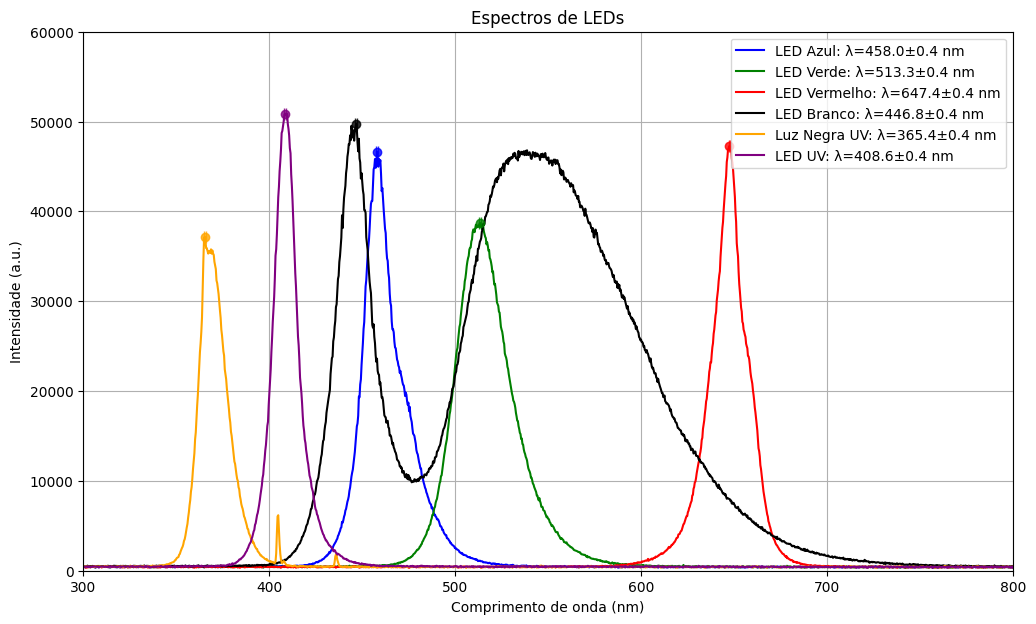

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Lista de arquivos e seus labels
files = [
    ('/content/drive/MyDrive/F740/Cópia de LED_AZUL_458,32_2.txt', 'LED Azul'),
    ('/content/drive/MyDrive/F740/LED_VERDE1_513,79.txt', 'LED Verde'),
    ('/content/drive/MyDrive/F740/LED_VERMELHO_648,78.txt', 'LED Vermelho'),
    ('/content/drive/MyDrive/F740/LED_BRANCO_454,99.txt', 'LED Branco'),
    ('/content/drive/MyDrive/F740/LUZ_NEGRA_ULTRA_VIOLETA.txt', 'Luz Negra UV'),
    ('/content/drive/MyDrive/F740/LED_UV_409,93.txt', 'LED UV')
]

# Cores para cada curva
colors = ['blue', 'green', 'red', 'black', 'orange', 'purple']

plt.figure(figsize=(12,7))

for i, (file_path, label) in enumerate(files):
    # Função para limpar números (remover BOM e substituir vírgula por ponto)
    def clean_number(x):
        return float(x.strip().replace('\ufeff', '').replace(',', '.'))

    # Ler os dados
    data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
    wavelength = data[:,0]  # nm
    intensity = data[:,1]

    # Encontrar pico principal
    idx_max = np.argmax(intensity)
    lambda_peak = wavelength[idx_max]
    intensity_peak = intensity[idx_max]

    # Estimar incerteza apenas no eixo x
    sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel

    # Criar label incluindo apenas o pico de comprimento de onda
    label_with_peak = f"{label}: λ={lambda_peak:.1f}±{sigma_lambda:.1f} nm"

    # Plotar curva com pico destacado e barra de erro apenas no eixo x
    plt.plot(wavelength, intensity, label=label_with_peak, color=colors[i])
    plt.errorbar(lambda_peak, intensity_peak,
                 xerr=sigma_lambda,
                 fmt='o', color=colors[i], ecolor=colors[i], elinewidth=2, capsize=4, alpha=0.8)

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.xlim(300, 800)
plt.ylim(0, 60000)
plt.title('Espectros de LEDs')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


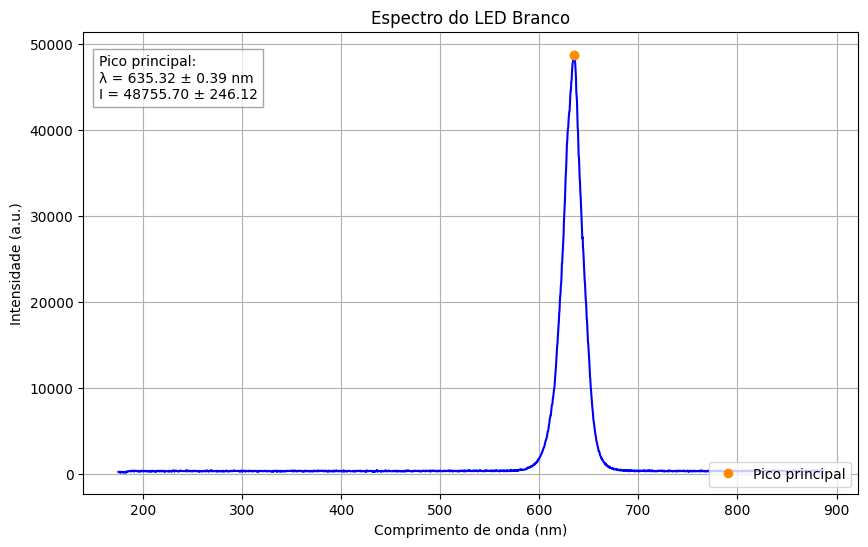

Pico principal: λ = 635.32 ± 0.39 nm, I = 48755.70 ± 246.12


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/planck/LED_VERMELHO_CALIBRADO_1,994V.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='lower right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED Branco')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")


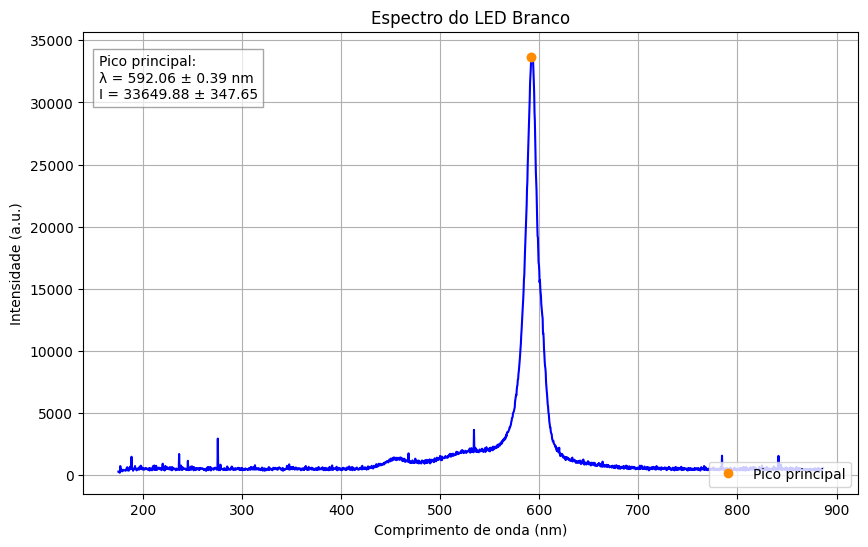

Pico principal: λ = 592.06 ± 0.39 nm, I = 33649.88 ± 347.65


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/planck/LED_AMARELO_ALINHADO_2.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='lower right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED amarelo')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")


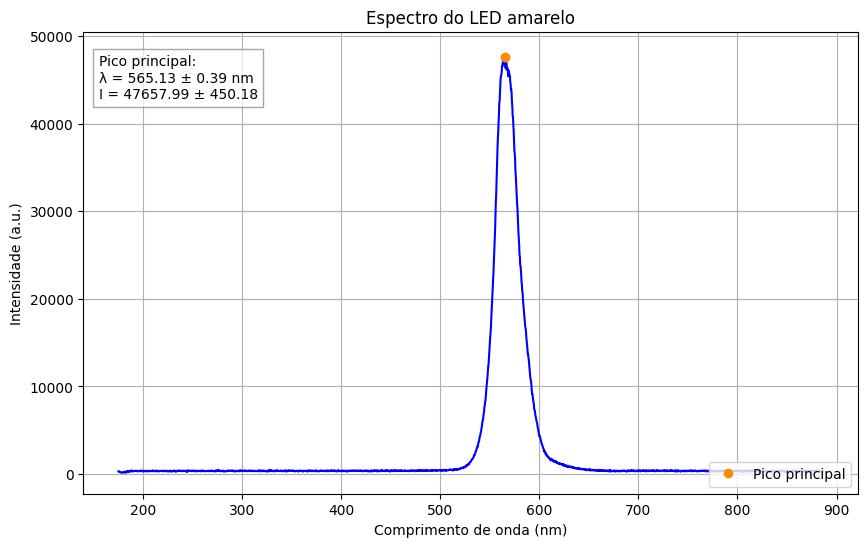

Pico principal: λ = 565.13 ± 0.39 nm, I = 47657.99 ± 450.18


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/planck/LED_VERDE_CALIBRADO_2,486V.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='lower right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED amarelo')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")


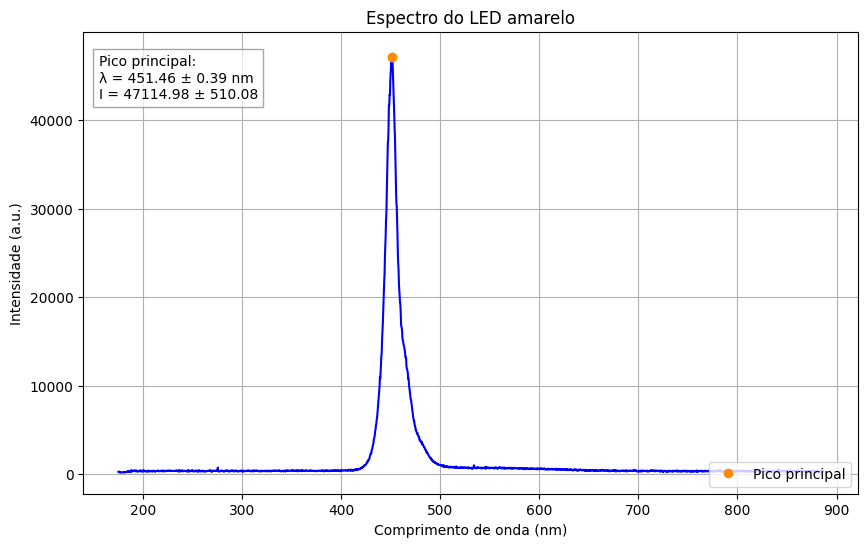

Pico principal: λ = 451.46 ± 0.39 nm, I = 47114.98 ± 510.08


In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Caminho do arquivo
file_path = '/content/drive/MyDrive/F740/planck/LED_AZUL_CALIBRADO_2,915V.txt'

# Função para limpar números (remover BOM e substituir vírgula por ponto)
def clean_number(x):
    return float(x.strip().replace('\ufeff', '').replace(',', '.'))

# Ler os dados
data = np.loadtxt(file_path, converters={0: clean_number, 1: clean_number})
wavelength = data[:,0]  # nm
intensity = data[:,1]

# Encontrar o pico principal
idx_max = np.argmax(intensity)
lambda_peak = wavelength[idx_max]
intensity_peak = intensity[idx_max]

# Estimar incertezas
sigma_lambda = wavelength[1] - wavelength[0]  # ±1 pixel
sigma_intensity = np.std(intensity[max(0, idx_max-2):idx_max+3])  # ±2 pontos vizinhos

# Plotar espectro com o pico destacado
plt.figure(figsize=(10,6))
# Curva do espectro
line_curve, = plt.plot(wavelength, intensity, label='Espectro', color='blue')
# Pico principal
line_peak, = plt.plot(lambda_peak, intensity_peak, 'o', color='darkorange', label='Pico principal')
# Barra de erro
err_peak = plt.errorbar(lambda_peak, intensity_peak,
                        xerr=sigma_lambda, yerr=sigma_intensity,
                        fmt='o', color='darkorange', alpha=0.5)

# Legenda da curva no canto superior esquerdo
plt.legend(handles=[line_curve], loc='upper left')

# Legenda do pico no canto inferior direito
plt.legend(handles=[line_peak], loc='lower right')

# Texto do pico no canto superior esquerdo
plt.text(0.02, 0.95,  # coordenadas relativas (x, y) no eixo [0,1]
         f'Pico principal:\nλ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm\n'
         f'I = {intensity_peak:.2f} ± {sigma_intensity:.2f}',
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top',
         color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))

plt.xlabel('Comprimento de onda (nm)')
plt.ylabel('Intensidade (a.u.)')
plt.title('Espectro do LED amarelo')
plt.grid(True)
plt.show()

print(f"Pico principal: λ = {lambda_peak:.2f} ± {sigma_lambda:.2f} nm, "
      f"I = {intensity_peak:.2f} ± {sigma_intensity:.2f}")
